# 01 — Inspect sensors, geography and masks

**Question:** what enters the retrieval model, and what metadata supports a positive pair?

The default data are tiny generated GeoTIFFs with known geographic extents,
two SAR channels and thirteen optical channels. Their visual patterns and
land-cover names are synthetic labels. The setup calls reusable package
functions and records a seed, config and versions. It creates local fixtures
only when absent; it performs no network access.

For real imagery, follow `docs/data_sources.md`, build a local scene manifest,
and replace `manifest_path` deliberately while removing the synthetic assertion.
Never call a real-data result synthetic or a synthetic result satellite evidence.

In [1]:
from pathlib import Path
import json, sys, platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists() and (p / "src/crosssense").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from crosssense.config import load_config, save_config
from crosssense.logging_config import configure_logging
from crosssense.data.synthetic import create_synthetic_fixture
from crosssense.data.pairing import prepare_pairs
from crosssense.data.dataset import load_manifest, load_pair_arrays, PairedPatchDataset
from crosssense.models.training import set_seed

config = load_config(ROOT / "configs/default.yaml")
config.training.device = "cpu"
set_seed(config.seed)
log_path = configure_logging(ROOT / "outputs/logs", "INFO", "notebook-01")
WORK = ROOT / "outputs/notebook_demo"
WORK.mkdir(parents=True, exist_ok=True)
save_config(config, WORK / "config.yaml")
scenes_path = WORK / "synthetic/scenes.csv"
if not scenes_path.exists():
    scenes_path = create_synthetic_fixture(WORK / "synthetic", config.data, config.seed)
manifest_path = WORK / "processed/pairs.csv"
if not manifest_path.exists():
    manifest_path = prepare_pairs(scenes_path, WORK / "processed", config.data, config.seed)
frame = load_manifest(manifest_path)
assert set(frame.source) == {"synthetic"}, "This default notebook is explicitly a synthetic demonstration"
display(Markdown("**SYNTHETIC PIPELINE TEST — no real satellite observations.**"))
display(pd.DataFrame([{"python": platform.python_version(), "numpy": version("numpy"), "torch": version("torch"), "rasterio": version("rasterio"), "seed": config.seed, "device": config.training.device}]))
display(config.to_dict())

**SYNTHETIC PIPELINE TEST — no real satellite observations.**

,python,numpy,torch,rasterio,seed,device
0,3.12.16,2.5.5,2.10.0,1.4.4,42,cpu


{'seed': 42,
 'data': {'patch_size': 32,
  'stride': 32,
  'resolution_m': 10.0,
  'target_crs': 'EPSG:32643',
  'sar_bands': [1, 2],
  'optical_bands': [2, 3, 4, 8],
  'sar_units': 'db',
  'sar_clip_db': [-30.0, 5.0],
  'optical_scale': 10000.0,
  'optical_clip': [0.0, 1.0],
  'min_valid_fraction': 0.8,
  'max_cloud_fraction': 0.2,
  'max_time_gap_days': 7.0,
  'min_overlap': 0.9,
  'geographic_exclusion_m': 500.0,
  'block_size_m': 10000.0,
  'split_buffer_m': 500.0,
  'split_fractions': [0.6, 0.2, 0.2],
  'scene_manifest': None,
  'require_cloud_mask': False,
  'allow_author_pairs_without_time': False},
 'model': {'sar_channels': 2,
  'optical_channels': 4,
  'embedding_dim': 32,
  'width': 16,
  'freeze_backbones': False},
 'training': {'batch_size': 8,
  'epochs': 4,
  'lr': 0.001,
  'temperature': 0.1,
  'device': 'cpu',
  'patience': 5,
  'num_workers': 0},
 'logging': {'level': 'INFO', 'output_dir': 'outputs/logs'}}

## Raster inspection and raw scene provenance

GeoTIFF metadata are inspected by `inspect_raster`; malformed files, missing CRS
and invalid band selections raise contextual errors. Raster values are not RGB
photographs: SAR uses calibrated dB here, while optical DN values use the explicit
source scale. Projection and masks matter before any image comparison.

In [2]:
from dataclasses import asdict
from crosssense.data.preprocess import inspect_raster
scenes = pd.read_csv(scenes_path)
display(scenes[["scene_id", "sensor", "timestamp", "source", "band_names", "land_cover"]])
metadata = []
for row in scenes.head(2).itertuples():
    path = Path(row.path)
    path = path if path.is_absolute() else scenes_path.parent / path
    metadata.append({"sensor": row.sensor, **asdict(inspect_raster(path))})
display(pd.DataFrame(metadata))

,scene_id,sensor,timestamp,source,band_names,land_cover
0,synthetic-region0-sar,sar,2024-01-10T00:00:00Z,synthetic,"[""VV"", ""VH""]",synthetic_urban
1,synthetic-region0-optical,optical,2024-01-12T00:00:00Z,synthetic,"[""B1"", ""B2"", ""B3"", ""B4"", ""B5"", ""B6"", ""B7"", ""B8...",synthetic_urban
2,synthetic-region1-sar,sar,2024-01-10T00:00:00Z,synthetic,"[""VV"", ""VH""]",synthetic_rural
3,synthetic-region1-optical,optical,2024-01-12T00:00:00Z,synthetic,"[""B1"", ""B2"", ""B3"", ""B4"", ""B5"", ""B6"", ""B7"", ""B8...",synthetic_rural
4,synthetic-region2-sar,sar,2024-01-10T00:00:00Z,synthetic,"[""VV"", ""VH""]",synthetic_water
5,synthetic-region2-optical,optical,2024-01-12T00:00:00Z,synthetic,"[""B1"", ""B2"", ""B3"", ""B4"", ""B5"", ""B6"", ""B7"", ""B8...",synthetic_water
6,synthetic-region3-sar,sar,2024-01-10T00:00:00Z,synthetic,"[""VV"", ""VH""]",synthetic_urban
7,synthetic-region3-optical,optical,2024-01-12T00:00:00Z,synthetic,"[""B1"", ""B2"", ""B3"", ""B4"", ""B5"", ""B6"", ""B7"", ""B8...",synthetic_urban
8,synthetic-region4-sar,sar,2024-01-10T00:00:00Z,synthetic,"[""VV"", ""VH""]",synthetic_rural
9,synthetic-region4-optical,optical,2024-01-12T00:00:00Z,synthetic,"[""B1"", ""B2"", ""B3"", ""B4"", ""B5"", ""B6"", ""B7"", ""B8...",synthetic_rural


,sensor,path,crs,bounds,resolution,width,height,bands,nodata,invalid_fraction
0,sar,C:\Users\agent\Downloads\coding\CrossSense\out...,EPSG:32643,"(450000.0, 1449360.0, 450640.0, 1450000.0)","(10.0, 10.0)",64,64,2,-9999.0,0.0
1,optical,C:\Users\agent\Downloads\coding\CrossSense\out...,EPSG:32643,"(450000.0, 1449360.0, 450640.0, 1450000.0)","(10.0, 10.0)",64,64,13,-9999.0,0.0


## Paired normalized patches and common validity

This plot shows the tensors actually loaded for training: VV/VH after dB clipping,
B4/B3/B2 as an RGB diagnostic, and the common mask. Optical display brightness
is multiplied by 2.5 only for visualization. Invalid model pixels are zero-filled;
the mask preserves their distinction from valid low values.

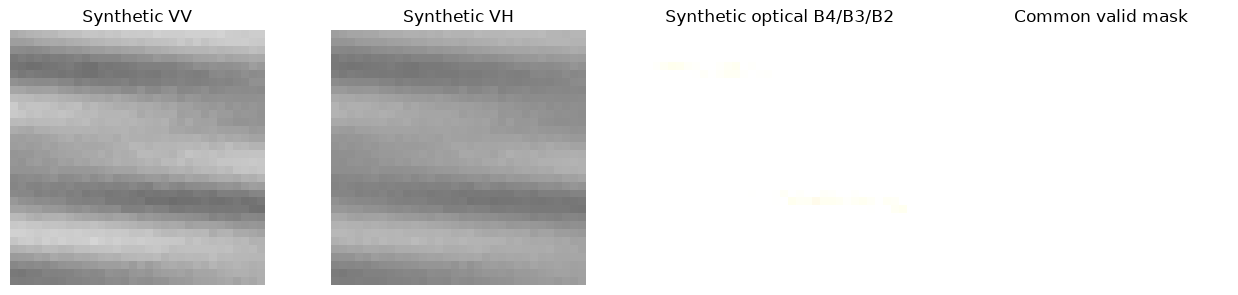

,pair_id,source,crs,x,y,time_gap_days,cloud_fraction,valid_fraction,split
0,pair-d8c86b729d3b68a2dbd1,synthetic,EPSG:32643,450160.0,1449840.0,2.0,0.0,1.0,train
1,pair-d528ec489cb91ee1b333,synthetic,EPSG:32643,450480.0,1449840.0,2.0,0.0,1.0,train
2,pair-6408e4bfcbc4202a99a0,synthetic,EPSG:32643,450160.0,1449520.0,2.0,0.0,1.0,train
3,pair-c0abb4251b2f5f5be7d7,synthetic,EPSG:32643,450480.0,1449520.0,2.0,0.0,1.0,train
4,pair-e4da00fe001c18eff233,synthetic,EPSG:32643,480160.0,1449840.0,2.0,0.0,1.0,validation


In [3]:
sar, optical, mask = load_pair_arrays(frame.iloc[0])
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
axes[0].imshow(np.ma.array(sar[0], mask=~mask), cmap="gray", vmin=0, vmax=1)
axes[1].imshow(np.ma.array(sar[1], mask=~mask), cmap="gray", vmin=0, vmax=1)
rgb = np.moveaxis(np.clip(optical[[2,1,0]] * 2.5, 0, 1), 0, -1)
rgb[~mask] = 0
axes[2].imshow(rgb)
axes[3].imshow(mask, cmap="gray", vmin=0, vmax=1)
for ax, title in zip(axes, ["Synthetic VV", "Synthetic VH", "Synthetic optical B4/B3/B2", "Common valid mask"]):
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
display(frame[["pair_id", "source", "crs", "x", "y", "time_gap_days", "cloud_fraction", "valid_fraction", "split"]].head())

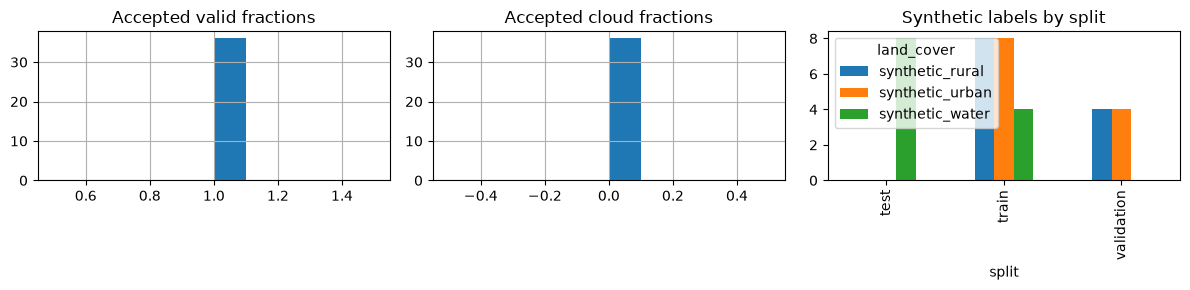

**Observed in this execution:** 36 accepted synthetic pairs, SAR shape `(2, 32, 32)`, optical shape `(4, 32, 32)`, mask shape `(32, 32)`. Logs: `C:\Users\agent\Downloads\coding\CrossSense\outputs\logs\notebook-01.log`. These observations validate the fixture and data path; they do not measure real-sensor retrieval quality.

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
frame.valid_fraction.hist(ax=axes[0]); axes[0].set_title("Accepted valid fractions")
frame.cloud_fraction.hist(ax=axes[1]); axes[1].set_title("Accepted cloud fractions")
frame.groupby(["split", "land_cover"]).size().unstack(fill_value=0).plot.bar(ax=axes[2])
axes[2].set_title("Synthetic labels by split"); plt.tight_layout(); plt.show()
display(Markdown(f"**Observed in this execution:** {len(frame)} accepted synthetic pairs, SAR shape `{sar.shape}`, optical shape `{optical.shape}`, mask shape `{mask.shape}`. Logs: `{log_path}`. These observations validate the fixture and data path; they do not measure real-sensor retrieval quality."))